pandas will help load, select and transform the mushroom records

matplotlib.pyplot creates the distribution charts and scatterplots.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

Loading the mushroom data from UCI and selecting wheater its edible, cap shape, and odor. I gave the colums proper naes and will only preview the first five rows.

In [ ]:
url= "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"
mushrooms = pd.read_csv(
    url,
    header=None,
    usecols=[0, 4, 5]
)
mushrooms.columns = ["edibility", "bruises", "odor"]
mushrooms.head()

,edibility,bruises,odor
0,p,t,p
1,e,t,a
2,e,t,l
3,p,t,p
4,e,f,n


Checking the number of rows and columns within my DataFrame. Using this as a confirmation that the data includes what I am looking for.

In [ ]:
mushrooms.shape

(8124, 3)

Checking the codes in each column before putting numbers in their place

In [ ]:
print("Edibility:", mushrooms["edibility"].unique())
print("Bruises:", mushrooms["bruises"].unique())
print("Odor:", mushrooms["odor"].unique())

Edibility: ['p' 'e']
Bruises: ['t' 'f']
Odor: ['p' 'a' 'l' 'n' 'f' 'c' 'y' 's' 'm']


Creating the dictionaries to match each letter code to a number.

 **Edible** = 0

 **Poisonous** = 1

 0 = **No bruises**

 1 = **bruises**

 Each odor receives its own numerical value




In [ ]:
edibility_codes = { "e": 0, "p": 1}
bruises_codes = { "f": 0, "t": 1}
odor_codes = {
    "a": 0, # almond
    "l": 1, # anise
    "c": 2, #creosote
    "y": 3, # fishy
    "f": 4, #foul
    "m": 5, #musty
    "n": 6, #none
    "p": 7, #pungent
    "s": 8, #spicy
    }

Making a copy of the DataFrame and replacing the letters with the numbers as defined in my dictionaries. previewing the first five rows

In [13]:
mushrooms_numeric = mushrooms.copy()

mushrooms_numeric["edibility"] = mushrooms["edibility"].map(edibility_codes)
mushrooms_numeric["bruises"] = mushrooms["bruises"].map(bruises_codes)
mushrooms_numeric["odor"] = mushrooms["odor"].map(odor_codes)
mushrooms_numeric.head()

,edibility,bruises,odor
0,1,1,7
1,0,1,0
2,0,1,1
3,1,1,7
4,0,0,6


In [14]:
print("missing values")
print(mushrooms_numeric.isna().sum())
print("\ndata types:")
print(mushrooms_numeric.dtypes)

missing values
edibility    0
bruises      0
odor         0
dtype: int64

data types:
edibility    int64
bruises      int64
odor         int64
dtype: object


Counting how many mushrooms are labeled as edible and poisonous. Displayed as a bar chart to compare the two

edibility
0    4208
1    3916
Name: count, dtype: int64


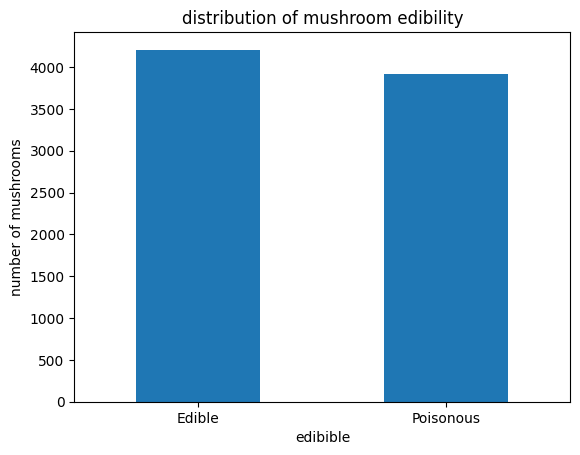

In [33]:
edibility_counts = mushrooms_numeric["edibility"].value_counts().sort_index()
print(edibility_counts)
edibility_counts.plot(kind="bar")
plt.title("distribution of mushroom edibility")
plt.xlabel("edibible")
plt.ylabel("number of mushrooms")
plt.xticks([0, 1], ["Edible", "Poisonous"], rotation=0)
plt.show()

Counting how many mushrooms, bruise and how many don't

bruises
0    4748
1    3376
Name: count, dtype: int64


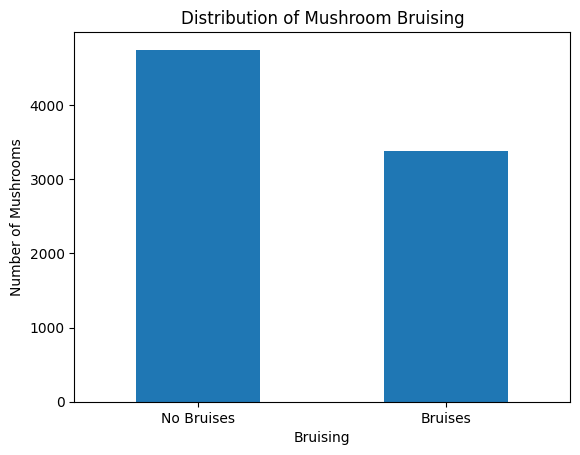

In [17]:
bruises_counts = mushrooms_numeric["bruises"].value_counts().sort_index()
print(bruises_counts)
bruises_counts.plot(kind="bar")
plt.title("Distribution of Mushroom Bruising")
plt.xlabel("Bruising")
plt.ylabel("Number of Mushrooms")
plt.xticks([0, 1], ["No Bruises", "Bruises"], rotation=0)
plt.show()

Counting the records in each odor category, displaying them in the same manner as the previous cells. Rotated the labels on the x-axis so they'd fit.

odor
0     400
1     400
2     192
3     576
4    2160
5      36
6    3528
7     256
8     576
Name: count, dtype: int64


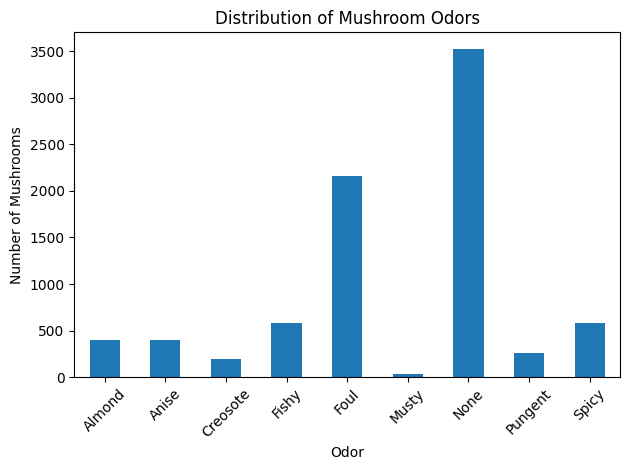

In [22]:
odor_counts = mushrooms_numeric["odor"].value_counts().sort_index()
print(odor_counts)
odor_counts.plot(kind="bar")
plt.title("Distribution of Mushroom Odors")
plt.xlabel("Odor")
plt.ylabel("Number of Mushrooms")
plt.xticks(
    range(9),
    ["Almond", "Anise", "Creosote", "Fishy", "Foul", "Musty", "None", "Pungent", "Spicy"],
    rotation=45
)
plt.tight_layout()
plt.show()

Creating the scatterplot to compare odor eith edibility.

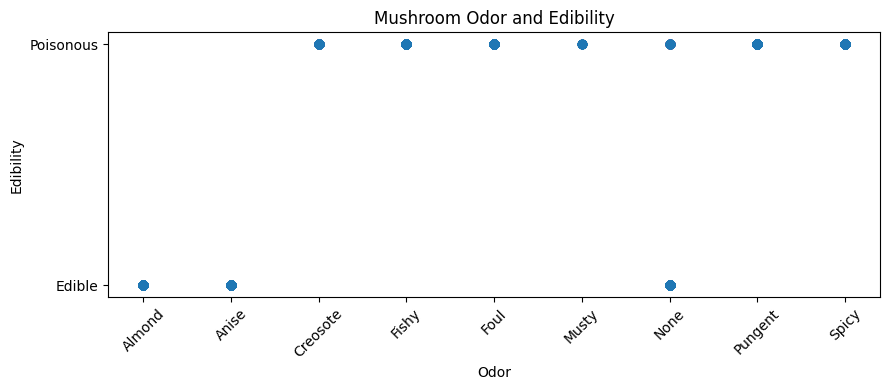

In [26]:
plt.figure(figsize=(9,4))
plt.scatter(
    mushrooms_numeric["odor"],
    mushrooms_numeric["edibility"],
    alpha=0.3
)
plt.title("Mushroom Odor and Edibility")
plt.xlabel("Odor")
plt.ylabel("Edibility")
plt.xticks(
    range(9),
    ["Almond", "Anise", "Creosote", "Fishy", "Foul", "Musty", "None", "Pungent", "Spicy"],
    rotation=45
)
plt.yticks([0,1], ["Edible", "Poisonous"])
plt.tight_layout()
plt.show()

Creating a scatterplot to compare bruising with edibility. Ill show if mushrooms with/without brusing also appear as edible poisonous or both

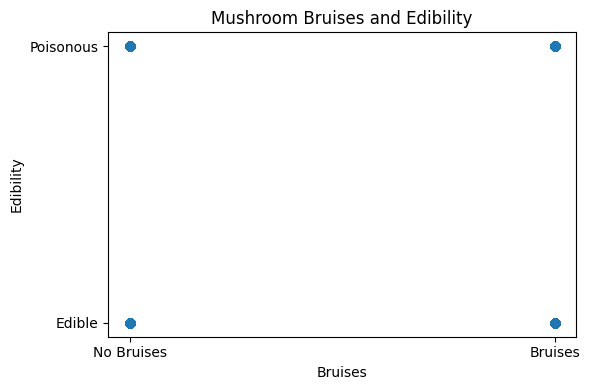

In [27]:
plt.figure(figsize=(6,4))
plt.scatter(
    mushrooms_numeric["bruises"],
    mushrooms_numeric["edibility"],
    alpha=0.3
)
plt.title("Mushroom Bruises and Edibility")
plt.xlabel("Bruises")
plt.ylabel("Edibility")
plt.xticks([0,1], ["No Bruises", "Bruises"])
plt.yticks([0,1], ["Edible", "Poisonous"])
plt.tight_layout()
plt.show()

Creating a table to show how many edible and poisonous mushrooms occur in each odor category

In [31]:
odor_comparison=pd.crosstab(
    mushrooms_numeric["odor"],
    mushrooms_numeric["edibility"]

)
odor_comparison = odor_comparison.rename(
    index={
    0: "Almond", 1: "Anise", 2: "Creosote", 3: "Fishy", 4: "Foul", 5: "Musty", 6: "None", 7: "Pungent", 8: "Spicy"},
                                         columns={0: "Edible", 1: "Poisonous"
                                         },)
odor_comparison

edibility,Edible,Poisonous
odor,,
Almond,400,0
Anise,400,0
Creosote,0,192
Fishy,0,576
Foul,0,2160
Musty,0,36
None,3408,120
Pungent,0,256
Spicy,0,576


Counting edible and poisonous mushrooms in each bruising category. Showing what was hidden in the earlier chart due tooverlapping in the scatterplot

In [37]:
bruises_comparison = pd.crosstab(
    mushrooms_numeric["bruises"],
    mushrooms_numeric["edibility"]
)
bruises_comparison = bruises_comparison.rename(
    index={0: "No Bruises", 1: "Bruises"},
    columns={0: "Edible", 1: "Poisonous"}
)
bruises_comparison

edibility,Edible,Poisonous
bruises,,
No Bruises,1456,3292
Bruises,2752,624


Odor appears to be a useful predictor of edibility in this dataset. Almond and Anise odors occured only among edible mushrooms.

Those without odor included both edible and poisonous records, so odor did not create a division between the grous.

Bruising also appears useful. Among mushrooms with bruises, I found that 2,752 mushrooms were edible, but 624 were poisonous. The differences suggest a relationship between bruising and edibility, but alone cannot classify every record correctly.

The comparisons, show that odor appears to distinguish the groups more clearly compared to bruising.